#### Domain – Retail/Fashion
#### focus – Optimize sales
#### Business challenge/requirement
Fyntra is the largest online clothing company in USA. It sells clothing online,but they also have in-store style and clothing advice sessions. Customers come into the store, have sessions/meetings with a personal stylist, then can go home and order either on a mobile app or website for the clothes they want.Company wants to decidewhether to focus the effort on mobile app experience or its website. As a drastic measure it is also evaluating to shut down the website. You as a ML expert in the team will help the company make the right decision.
#### Business benefits
Increase in profits as thefocus on the optimal sales channel will result into the higher top line and thehigher bottom line

In [56]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import train_test_split

plt.style.use("default")

In [57]:
shop_df = pd.read_csv('./files/FyntraCustomerData.csv')
shop_df

,Email,Address,Avatar,Avg_Session_Length,Time_on_App,Time_on_Website,Length_of_Membership,Yearly_Amount_Spent
0,mstephenson@fernandez.com,"835 Frank Tunnel\nWrightmouth, MI 82180-9605",Violet,34.497268,12.655651,39.577668,4.082621,587.951054
1,hduke@hotmail.com,"4547 Archer Common\nDiazchester, CA 06566-8576",DarkGreen,31.926272,11.109461,37.268959,2.664034,392.204933
2,pallen@yahoo.com,"24645 Valerie Unions Suite 582\nCobbborough, D...",Bisque,33.000915,11.330278,37.110597,4.104543,487.547505
3,riverarebecca@gmail.com,"1414 David Throughway\nPort Jason, OH 22070-1220",SaddleBrown,34.305557,13.717514,36.721283,3.120179,581.852344
4,mstephens@davidson-herman.com,"14023 Rodriguez Passage\nPort Jacobville, PR 3...",MediumAquaMarine,33.330673,12.795189,37.536653,4.446308,599.406092
...,...,...,...,...,...,...,...,...
495,lewisjessica@craig-evans.com,"4483 Jones Motorway Suite 872\nLake Jamiefurt,...",Tan,33.237660,13.566160,36.417985,3.746573,573.847438
496,katrina56@gmail.com,"172 Owen Divide Suite 497\nWest Richard, CA 19320",PaleVioletRed,34.702529,11.695736,37.190268,3.576526,529.049004
497,dale88@hotmail.com,"0787 Andrews Ranch Apt. 633\nSouth Chadburgh, ...",Cornsilk,32.646777,11.499409,38.332576,4.958264,551.620146
498,cwilson@hotmail.com,"680 Jennifer Lodge Apt. 808\nBrendachester, TX...",Teal,33.322501,12.391423,36.840086,2.336485,456.469510


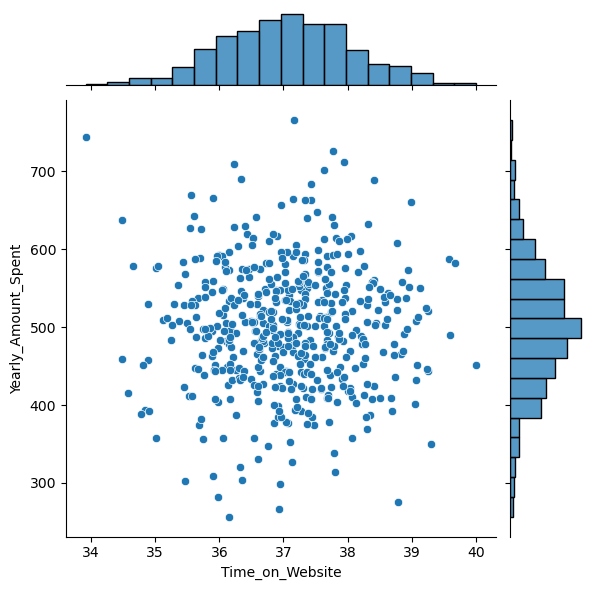

In [58]:
# Compute --Use seaborn to create a jointplot to compare the Time on Website and Yearly Amount Spent columns. Is there a correlation?
sns.jointplot(x='Time_on_Website', y='Yearly_Amount_Spent', data=shop_df)
plt.show()

No Relation


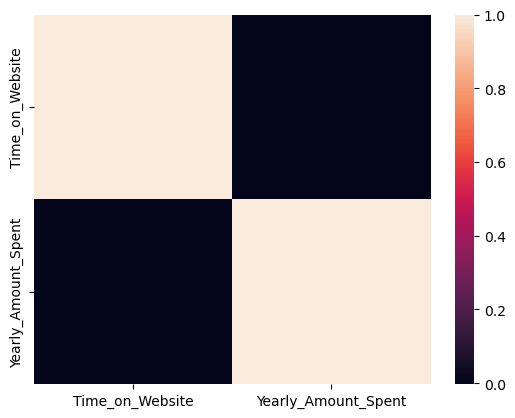

In [59]:
sns.heatmap(shop_df[['Time_on_Website','Yearly_Amount_Spent']].corr())
if shop_df['Time_on_Website'].corr(shop_df['Yearly_Amount_Spent'])<1:
    print("No Relation")
else:
    print("Positive Relation")

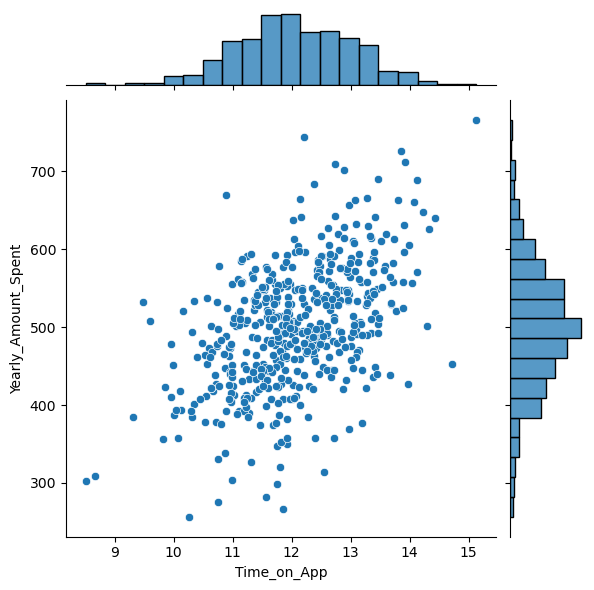

In [60]:
# Compute –Do the same as above but now with Time on App and Yearly Amount Spent. Is this correlation stronger than 1stOne?
sns.jointplot(x='Time_on_App', y='Yearly_Amount_Spent', data=shop_df)
plt.show()

Stronger than 1st one


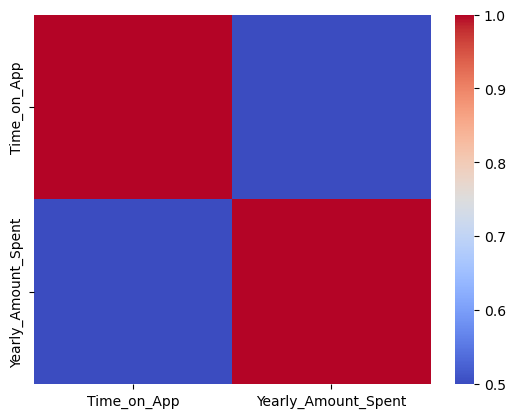

In [61]:
sns.heatmap(shop_df[['Time_on_App','Yearly_Amount_Spent']].corr(),cmap='coolwarm')
if shop_df['Yearly_Amount_Spent'].corr(shop_df['Time_on_App'])>shop_df['Time_on_Website'].corr(shop_df['Yearly_Amount_Spent']):
    print("Stronger than 1st one")
else:
    print("Not Stronger")

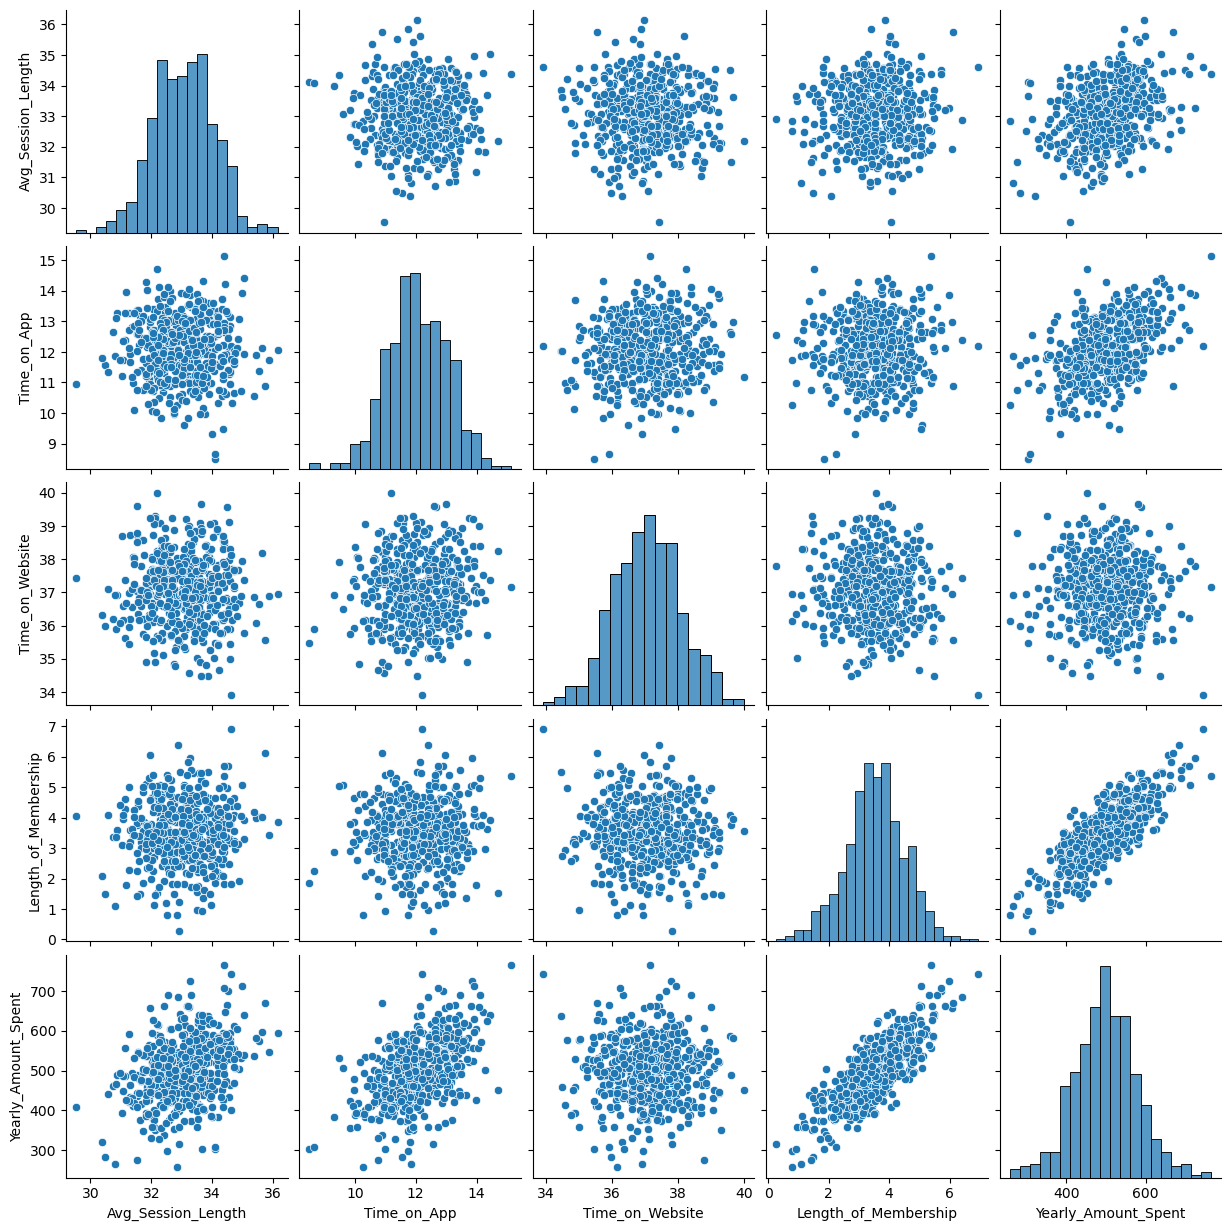

In [62]:
# Compute --Explore types of relationships across the entire data set using pairplot .
# Based off this plot what looks to be the most correlated feature with Yearly Amount Spent?
# answer : Length_of_Membership because with the time the length also increases (means directly proportional)

sns.pairplot(shop_df)
plt.show()

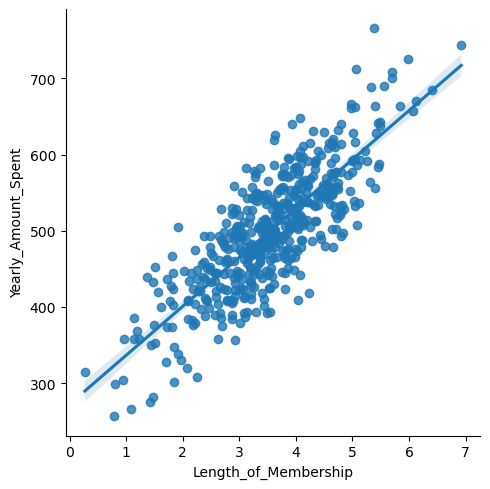

In [63]:
# Compute –Create linear model plot of Length of Membership and Yearly Amount Spent. Does the data fits well in linear plot?
sns.lmplot(data=shop_df,x='Length_of_Membership',y='Yearly_Amount_Spent')
plt.show()

In [64]:
# Compute –Train and Test the data and answer multiple questions --What is the use of random_state=85?
X = shop_df[['Avg_Session_Length', 'Time_on_App', 'Time_on_Website', 'Length_of_Membership']]
y = shop_df['Yearly_Amount_Spent']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=85)

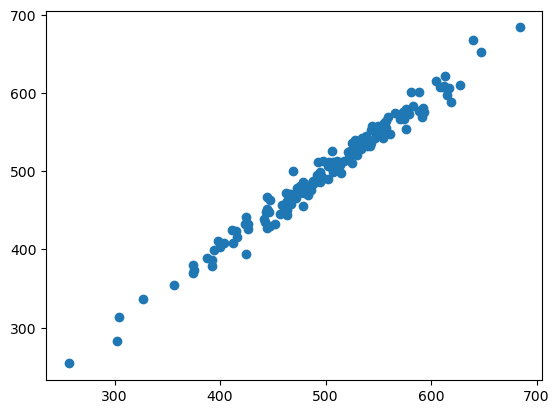

In [65]:
# Compute –Predict the data and do a scatter plot. Check if actual and predicted data match?
lm = LinearRegression()
lm.fit(X_train, y_train)
y_pred = lm.predict(X_test)
plt.scatter(y_test,y_pred)
plt.show()

In [66]:
# What is the value of Root Mean Squared Error?
root_mean_squared_error(y_test,y_pred)

10.572658672879324